In [2]:

import pandas as pd
from pathlib import Path
files = list(Path.cwd().rglob("208 variable list.xlsx"))
print("Files found:", files)
df = pd.read_excel(files[0])
print("Dataset shape:", df.shape)
with pd.option_context("display.max_rows", 208):
    display(df)

print(df.columns.tolist())


Files found: [PosixPath('/Users/subodhshrestha/Downloads/explorelocal/HIT140-GROUP-PROJECT/Objective 2/208 variable list.xlsx')]
Dataset shape: (208, 14)


,Match_ID,Date,Stage,Team,Opponent,Goals_Scored,Team ranking,Opponent Ranking,Team Player Avg Age,Opponent Player Avg Age,Win,GF,GS,CS
0,1,2026-06-11,Group stage,Mexico,South Africa,2,14,60,26.29,26.81,0.6,1.0,-0.8,0.4
1,1,2026-06-11,Group stage,South Africa,Mexico,0,60,14,26.81,26.29,-0.6,-1.0,0.8,-0.4
2,2,2026-06-11,Group stage,South Korea,Czechia,2,25,40,27.65,27.03,0.0,-2.0,-0.2,0.4
3,2,2026-06-11,Group stage,Czechia,South Korea,1,40,25,27.03,27.65,0.0,2.0,0.2,-0.4
4,3,2026-06-12,Group stage,Canada,Bosnia and Herzegovina,1,30,64,25.81,26.38,0.4,0.6,-0.2,0.4
5,3,2026-06-12,Group stage,Bosnia and Herzegovina,Canada,1,64,30,26.38,25.81,-0.4,-0.6,0.2,-0.4
6,4,2026-06-12,Group stage,USA,Paraguay,4,17,41,26.38,27.80,-0.2,0.4,1.4,-0.4
7,4,2026-06-12,Group stage,Paraguay,USA,1,41,17,27.80,26.38,0.2,-0.4,-1.4,0.4
8,5,2026-06-13,Group stage,Haiti,Scotland,0,83,42,27.08,28.81,-0.2,-1.6,-0.2,0.0
9,5,2026-06-13,Group stage,Scotland,Haiti,1,42,83,28.81,27.08,0.2,1.6,0.2,0.0


['Match_ID', 'Date', 'Stage', 'Team', 'Opponent', 'Goals_Scored', 'Team ranking', 'Opponent Ranking', 'Team Player Avg Age', 'Opponent Player Avg Age', 'Win', 'GF', 'GS', 'CS']


In [3]:

print("Total observations:", len(df))
print("Total matches:", df["Match_ID"].nunique())
print("Total columns:", len(df.columns))


Total observations: 208
Total matches: 104
Total columns: 14


In [4]:

# Check column names
print("Column names:")
print(df.columns.tolist())

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check data types
print("\nData types:")
print(df.dtypes)

# Check dataset size
print("\nDataset shape:", df.shape)


Column names:
['Match_ID', 'Date', 'Stage', 'Team', 'Opponent', 'Goals_Scored', 'Team ranking', 'Opponent Ranking', 'Team Player Avg Age', 'Opponent Player Avg Age', 'Win', 'GF', 'GS', 'CS']

Missing values:
Match_ID                   0
Date                       0
Stage                      0
Team                       0
Opponent                   0
Goals_Scored               0
Team ranking               0
Opponent Ranking           0
Team Player Avg Age        0
Opponent Player Avg Age    0
Win                        0
GF                         0
GS                         0
CS                         0
dtype: int64

Data types:
Match_ID                     int64
Date                           str
Stage                          str
Team                           str
Opponent                       str
Goals_Scored                 int64
Team ranking                 int64
Opponent Ranking             int64
Team Player Avg Age        float64
Opponent Player Avg Age    float64
Win       

In [5]:

# Descriptive statistics for numerical columns
descriptive_stats = df.describe()

display(descriptive_stats.round(3))


,Match_ID,Goals_Scored,Team ranking,Opponent Ranking,Team Player Avg Age,Opponent Player Avg Age,Win,GF,GS,CS
count,208.000,208.000,208.000,208.000,208.000,208.000,208.000,208.000,208.000,208.000
mean,52.500,1.481,27.760,27.760,27.038,27.038,0.000,0.000,0.000,0.000
std,30.093,1.393,22.945,22.945,1.165,1.165,0.357,1.027,0.963,0.368
min,1.000,0.000,1.000,1.000,23.760,23.760,-1.000,-2.800,-2.800,-1.000
25%,26.750,0.000,8.750,8.750,26.362,26.362,-0.200,-0.650,-0.450,-0.200
50%,52.500,1.000,22.500,22.500,27.040,27.040,0.000,0.000,0.000,0.000
75%,78.250,2.000,41.000,41.000,27.730,27.730,0.200,0.650,0.450,0.200
max,104.000,7.000,85.000,85.000,29.540,29.540,1.000,2.800,2.800,1.000


,Goals_Scored,Team ranking,Opponent Ranking,Team Player Avg Age,Opponent Player Avg Age,Win,GF,GS,CS
Goals_Scored,1.000,-0.367,0.345,-0.102,-0.011,0.204,0.253,-0.153,0.028
Team ranking,-0.367,1.000,-0.119,0.152,0.016,-0.217,-0.191,0.165,-0.094
Opponent Ranking,0.345,-0.119,1.000,0.016,0.152,0.217,0.191,-0.165,0.094
Team Player Avg Age,-0.102,0.152,0.016,1.000,0.066,-0.049,-0.049,0.166,-0.142
Opponent Player Avg Age,-0.011,0.016,0.152,0.066,1.000,0.049,0.049,-0.166,0.142
Win,0.204,-0.217,0.217,-0.049,0.049,1.000,0.752,-0.627,0.489
GF,0.253,-0.191,0.191,-0.049,0.049,0.752,1.000,-0.226,-0.003
GS,-0.153,0.165,-0.165,0.166,-0.166,-0.627,-0.226,1.000,-0.733
CS,0.028,-0.094,0.094,-0.142,0.142,0.489,-0.003,-0.733,1.000


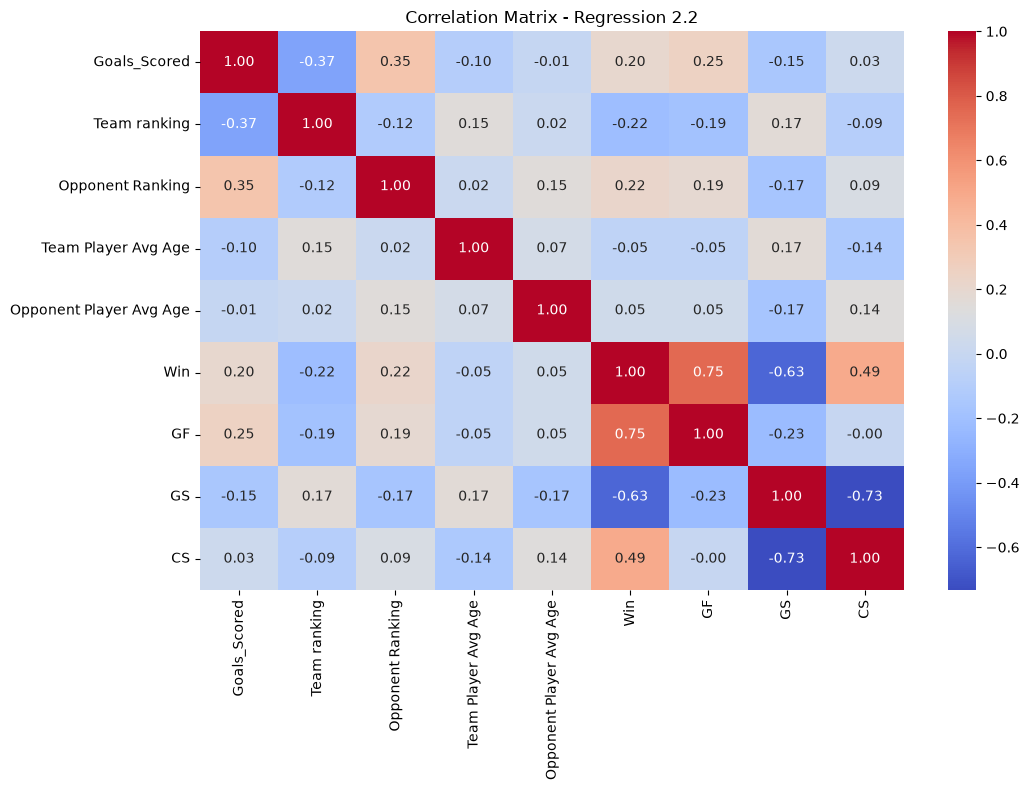

In [6]:

import matplotlib.pyplot as plt
import seaborn as sns

# Select the dependent and explanatory variables
columns = [
    "Goals_Scored",
    "Team ranking",
    "Opponent Ranking",
    "Team Player Avg Age",
    "Opponent Player Avg Age",
    "Win",
    "GF",
    "GS",
    "CS"
]

# Calculate correlations
correlation_matrix = df[columns].corr()

# Display correlation values
display(correlation_matrix.round(3))

# Create correlation heatmap
plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix - Regression 2.2")
plt.tight_layout()
plt.show()


In [7]:

import statsmodels.api as sm

# Eight explanatory variables
X = df[
    [
        "Team ranking",
        "Opponent Ranking",
        "Team Player Avg Age",
        "Opponent Player Avg Age",
        "Win",
        "GF",
        "GS",
        "CS"
    ]
]

# Dependent variable
y = df["Goals_Scored"]

# Add the intercept
X = sm.add_constant(X)

# Fit the regression model
model = sm.OLS(y, X).fit()

# Display the results
print(model.summary())


                            OLS Regression Results                            
Dep. Variable:           Goals_Scored   R-squared:                       0.261
Model:                            OLS   Adj. R-squared:                  0.232
Method:                 Least Squares   F-statistic:                     8.803
Date:                Wed, 14 Oct 2026   Prob (F-statistic):           2.74e-10
Time:                        19:07:46   Log-Likelihood:                -332.14
No. Observations:                 208   AIC:                             682.3
Df Residuals:                     199   BIC:                             712.3
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                     

In [8]:
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           Goals_Scored   R-squared:                       0.261
Model:                            OLS   Adj. R-squared:                  0.232
Method:                 Least Squares   F-statistic:                     8.803
Date:                Wed, 14 Oct 2026   Prob (F-statistic):           2.74e-10
Time:                        19:07:46   Log-Likelihood:                -332.14
No. Observations:                 208   AIC:                             682.3
Df Residuals:                     199   BIC:                             712.3
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                     

In [9]:

import numpy as np

# Generate predictions
df["Predicted_Goals"] = model.predict(X)

# Calculate residuals
df["Residual"] = (
    df["Goals_Scored"] - df["Predicted_Goals"]
)

# Calculate MAE and RMSE
mae = np.mean(np.abs(df["Residual"]))

rmse = np.sqrt(np.mean(df["Residual"] ** 2))

print("Mean Absolute Error (MAE):", round(mae, 4))
print("Root Mean Squared Error (RMSE):", round(rmse, 4))

display(df[
    ["Goals_Scored", "Predicted_Goals", "Residual"]
].head(10))


Mean Absolute Error (MAE): 0.9202
Root Mean Squared Error (RMSE): 1.1947


,Goals_Scored,Predicted_Goals,Residual
0,2,2.374408,-0.374408
1,0,0.704576,-0.704576
2,2,1.053426,0.946574
3,1,1.829522,-0.829522
4,1,2.086764,-1.086764
5,1,1.100905,-0.100905
6,4,1.904424,2.095576
7,1,1.043367,-0.043367
8,0,0.251417,-0.251417
9,1,2.462345,-1.462345
